In [1]:
# ============================================================
# CELL 1 — ENVIRONMENT AND GPU VERIFICATION
# ============================================================

import sys
import os
import torch
import torchvision

print("=" * 70)
print("ARTEN ABLATION STUDY — ENVIRONMENT VERIFICATION")
print("=" * 70)

print(f"Python executable : {sys.executable}")
print(f"Python version    : {sys.version.split()[0]}")
print(f"PyTorch version   : {torch.__version__}")
print(f"Torchvision       : {torchvision.__version__}")
print(f"CUDA available    : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"CUDA version      : {torch.version.cuda}")
    print(f"GPU device        : {torch.cuda.get_device_name(0)}")
    print(f"GPU count         : {torch.cuda.device_count()}")

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU memory        : {gpu_memory:.2f} GB")
else:
    print("WARNING: CUDA GPU is NOT available.")

print("=" * 70)

ARTEN ABLATION STUDY — ENVIRONMENT VERIFICATION
Python executable : /home/ex5/arten_env/bin/python
Python version    : 3.10.12
PyTorch version   : 2.14.1+cu130
Torchvision       : 0.29.1+cu130
CUDA available    : True
CUDA version      : 13.0
GPU device        : NVIDIA GeForce RTX 3060
GPU count         : 1
GPU memory        : 11.63 GB


In [2]:
# ============================================================
# CELL 2 — PROJECT PATHS
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path("/home/ex5/Desktop/ARTEN_Project")

TRAINING_PAIRS = PROJECT_ROOT / "TrainingPairs"
INPUT_DIR = TRAINING_PAIRS / "input"
TARGET_DIR = TRAINING_PAIRS / "target"

ABLATION_DIR = PROJECT_ROOT / "ARTEN_Ablation_Study"
SPLIT_DIR = ABLATION_DIR / "splits"
RESULTS_DIR = ABLATION_DIR / "results"

print("=" * 70)
print("ARTEN ABLATION STUDY — PROJECT PATHS")
print("=" * 70)

print(f"Project root   : {PROJECT_ROOT}")
print(f"Input directory: {INPUT_DIR}")
print(f"Target directory: {TARGET_DIR}")
print(f"Split directory : {SPLIT_DIR}")
print(f"Results directory: {RESULTS_DIR}")

print("\nPath existence check:")

for name, path in {
    "Project root": PROJECT_ROOT,
    "Input directory": INPUT_DIR,
    "Target directory": TARGET_DIR,
    "Ablation directory": ABLATION_DIR,
    "Split directory": SPLIT_DIR,
}.items():
    print(f"{name:20s}: {path.exists()}")

print("=" * 70)

ARTEN ABLATION STUDY — PROJECT PATHS
Project root   : /home/ex5/Desktop/ARTEN_Project
Input directory: /home/ex5/Desktop/ARTEN_Project/TrainingPairs/input
Target directory: /home/ex5/Desktop/ARTEN_Project/TrainingPairs/target
Split directory : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/splits
Results directory: /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results

Path existence check:
Project root        : True
Input directory     : True
Target directory    : True
Ablation directory  : True
Split directory     : True


In [3]:
# ============================================================
# CELL 3 — EXACT INPUT/TARGET PAIR VERIFICATION
# ============================================================

import os

# Collect PNG filenames
input_files = {
    f for f in os.listdir(INPUT_DIR)
    if f.lower().endswith(".png")
}

target_files = {
    f for f in os.listdir(TARGET_DIR)
    if f.lower().endswith(".png")
}

# Compare filenames
input_only = sorted(input_files - target_files)
target_only = sorted(target_files - input_files)

print("=" * 70)
print("ARTEN ABLATION STUDY — INPUT/TARGET PAIR VERIFICATION")
print("=" * 70)

print(f"Input PNG images       : {len(input_files):,}")
print(f"Target PNG images      : {len(target_files):,}")
print(f"Input-only files       : {len(input_only):,}")
print(f"Target-only files      : {len(target_only):,}")
print(f"Exact paired images    : {len(input_files & target_files):,}")

print("\nExpected:")
print("Input images           : 21,875")
print("Target images          : 21,875")
print("Input-only files       : 0")
print("Target-only files      : 0")

if (
    len(input_files) == 21_875
    and len(target_files) == 21_875
    and len(input_only) == 0
    and len(target_only) == 0
):
    print("\nPAIR VERIFICATION: PASSED")
else:
    print("\nPAIR VERIFICATION: FAILED")

    if input_only:
        print("\nExamples of input-only files:")
        print(input_only[:10])

    if target_only:
        print("\nExamples of target-only files:")
        print(target_only[:10])

print("=" * 70)

ARTEN ABLATION STUDY — INPUT/TARGET PAIR VERIFICATION
Input PNG images       : 21,875
Target PNG images      : 21,875
Input-only files       : 0
Target-only files      : 0
Exact paired images    : 21,875

Expected:
Input images           : 21,875
Target images          : 21,875
Input-only files       : 0
Target-only files      : 0

PAIR VERIFICATION: PASSED


In [4]:
# ============================================================
# CELL 4 — VERIFY 70:20:10 DATASET SPLIT
# ============================================================

import pandas as pd

TRAIN_SPLIT = SPLIT_DIR / "train_split.csv"
VAL_SPLIT = SPLIT_DIR / "validation_split.csv"
TEST_SPLIT = SPLIT_DIR / "test_split.csv"

train_df = pd.read_csv(TRAIN_SPLIT)
val_df = pd.read_csv(VAL_SPLIT)
test_df = pd.read_csv(TEST_SPLIT)

print("=" * 70)
print("ARTEN ABLATION STUDY — 70:20:10 SPLIT VERIFICATION")
print("=" * 70)

print(f"Training   : {len(train_df):,} images")
print(f"Validation : {len(val_df):,} images")
print(f"Testing    : {len(test_df):,} images")
print(f"Total      : {len(train_df) + len(val_df) + len(test_df):,} images")

print("\nExpected:")
print("Training   : 15,310")
print("Validation :  4,374")
print("Testing    :  2,191")
print("Total      : 21,875")

# Check duplicate filenames within each split
train_set = set(train_df["filename"])
val_set = set(val_df["filename"])
test_set = set(test_df["filename"])

# Check overlap between splits
train_val_overlap = train_set & val_set
train_test_overlap = train_set & test_set
val_test_overlap = val_set & test_set

print("\nOverlap checks:")
print(f"Train ∩ Validation : {len(train_val_overlap)}")
print(f"Train ∩ Test       : {len(train_test_overlap)}")
print(f"Validation ∩ Test  : {len(val_test_overlap)}")

# Final verification
split_counts_ok = (
    len(train_df) == 15_310
    and len(val_df) == 4_374
    and len(test_df) == 2_191
)

no_overlap = (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
)

if split_counts_ok and no_overlap:
    print("\n70:20:10 SPLIT VERIFICATION: PASSED")
else:
    print("\n70:20:10 SPLIT VERIFICATION: FAILED")

print("=" * 70)

ARTEN ABLATION STUDY — 70:20:10 SPLIT VERIFICATION
Training   : 15,310 images
Validation : 4,374 images
Testing    : 2,191 images
Total      : 21,875 images

Expected:
Training   : 15,310
Validation :  4,374
Testing    :  2,191
Total      : 21,875

Overlap checks:
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

70:20:10 SPLIT VERIFICATION: PASSED


In [5]:
# ============================================================
# CELL 5 — PYTORCH DATASET LOADER
# ============================================================

import cv2
import torch
from torch.utils.data import Dataset, DataLoader


class ARTENSplitDataset(Dataset):
    """
    Dataset loader for the controlled ARTEN ablation study.

    Each sample contains:
        input  = low-quality/input image
        target = corresponding reference image

    Images are converted:
        BGR -> RGB
        uint8 [0,255] -> float32 [0,1]
        HWC -> CHW
    """

    def __init__(self, dataframe, input_dir, target_dir):
        self.dataframe = dataframe.reset_index(drop=True)
        self.input_dir = input_dir
        self.target_dir = target_dir

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        filename = self.dataframe.iloc[index]["filename"]

        input_path = self.input_dir / filename
        target_path = self.target_dir / filename

        input_image = cv2.imread(str(input_path), cv2.IMREAD_COLOR)
        target_image = cv2.imread(str(target_path), cv2.IMREAD_COLOR)

        if input_image is None:
            raise FileNotFoundError(f"Input image not found: {input_path}")

        if target_image is None:
            raise FileNotFoundError(f"Target image not found: {target_path}")

        # Convert BGR -> RGB
        input_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB)
        target_image = cv2.cvtColor(target_image, cv2.COLOR_BGR2RGB)

        # Convert uint8 [0,255] -> float32 [0,1]
        input_image = torch.from_numpy(
            input_image.astype("float32") / 255.0
        ).permute(2, 0, 1)

        target_image = torch.from_numpy(
            target_image.astype("float32") / 255.0
        ).permute(2, 0, 1)

        return input_image, target_image


# Create datasets
train_dataset = ARTENSplitDataset(
    train_df,
    INPUT_DIR,
    TARGET_DIR
)

val_dataset = ARTENSplitDataset(
    val_df,
    INPUT_DIR,
    TARGET_DIR
)

test_dataset = ARTENSplitDataset(
    test_df,
    INPUT_DIR,
    TARGET_DIR
)

print("=" * 70)
print("PYTORCH DATASET LOADER")
print("=" * 70)

print(f"Training dataset   : {len(train_dataset):,}")
print(f"Validation dataset : {len(val_dataset):,}")
print(f"Testing dataset    : {len(test_dataset):,}")

print("=" * 70)

PYTORCH DATASET LOADER
Training dataset   : 15,310
Validation dataset : 4,374
Testing dataset    : 2,191


In [6]:
# ============================================================
# CELL 6 — DATALOADERS AND ONE-SAMPLE VERIFICATION
# ============================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Retrieve one batch from the training loader
sample_inputs, sample_targets = next(iter(train_loader))

print("=" * 70)
print("DATALOADER AND ONE-BATCH VERIFICATION")
print("=" * 70)

print(f"Batch size          : {BATCH_SIZE}")
print(f"Input batch shape   : {sample_inputs.shape}")
print(f"Target batch shape  : {sample_targets.shape}")

print(f"\nInput dtype         : {sample_inputs.dtype}")
print(f"Target dtype        : {sample_targets.dtype}")

print(f"\nInput minimum       : {sample_inputs.min().item():.6f}")
print(f"Input maximum       : {sample_inputs.max().item():.6f}")

print(f"Target minimum      : {sample_targets.min().item():.6f}")
print(f"Target maximum      : {sample_targets.max().item():.6f}")

# Basic checks
shape_ok = (
    sample_inputs.shape == (BATCH_SIZE, 3, 256, 256)
    and sample_targets.shape == (BATCH_SIZE, 3, 256, 256)
)

range_ok = (
    sample_inputs.min() >= 0
    and sample_inputs.max() <= 1
    and sample_targets.min() >= 0
    and sample_targets.max() <= 1
)

if shape_ok and range_ok:
    print("\nONE-BATCH DATA VERIFICATION: PASSED")
else:
    print("\nONE-BATCH DATA VERIFICATION: FAILED")

print("=" * 70)

DATALOADER AND ONE-BATCH VERIFICATION
Batch size          : 16
Input batch shape   : torch.Size([16, 3, 256, 256])
Target batch shape  : torch.Size([16, 3, 256, 256])

Input dtype         : torch.float32
Target dtype        : torch.float32

Input minimum       : 0.000000
Input maximum       : 1.000000
Target minimum      : 0.000000
Target maximum      : 1.000000

ONE-BATCH DATA VERIFICATION: PASSED


In [7]:
# ============================================================
# CELL 7 — ARTEN ARCHITECTURE
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class SpatialAttention(nn.Module):
    """
    Spatial attention module used in the original ARTEN architecture.
    """

    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=7,
            padding=3
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_pool = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_pool, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        attention = torch.cat(
            [avg_pool, max_pool],
            dim=1
        )

        attention = self.conv(attention)
        attention = self.sigmoid(attention)

        return attention


class ResidualAttentionBlock(nn.Module):
    """
    Residual convolutional block with optional spatial attention
    and optional residual connection.

    These switches allow controlled ablation of:
        1. Spatial Attention
        2. Residual Connections
    """

    def __init__(
        self,
        channels,
        use_attention=True,
        use_residual=True
    ):

        super().__init__()

        self.use_attention = use_attention
        self.use_residual = use_residual

        self.conv1 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        if self.use_attention:
            self.spatial_attention = SpatialAttention()

    def forward(self, x):

        residual = x

        out = self.conv1(x)
        out = self.relu(out)
        out = self.conv2(out)

        if self.use_attention:
            attention = self.spatial_attention(out)
            out = out * attention

        if self.use_residual:
            out = out + residual

        return out


class EncoderBlock(nn.Module):
    """
    Encoder block:
    Convolution -> BatchNorm -> ReLU ->
    Residual Attention Block -> MaxPool
    """

    def __init__(
        self,
        in_channels,
        out_channels,
        use_attention=True,
        use_residual=True
    ):

        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.bn = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.residual_attention = ResidualAttentionBlock(
            out_channels,
            use_attention=use_attention,
            use_residual=use_residual
        )

        self.pool = nn.MaxPool2d(2)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)

        x = self.residual_attention(x)

        pooled = self.pool(x)

        return x, pooled


class DecoderBlock(nn.Module):
    """
    Decoder block with transposed convolution and encoder skip connection.
    """

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels,
        use_attention=True,
        use_residual=True
    ):

        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        self.conv = nn.Conv2d(
            out_channels + skip_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.bn = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.residual_attention = ResidualAttentionBlock(
            out_channels,
            use_attention=use_attention,
            use_residual=use_residual
        )

    def forward(self, x, skip):

        x = self.up(x)

        # Safety check for spatial dimensions
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(
                x,
                size=skip.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat(
            [x, skip],
            dim=1
        )

        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)

        x = self.residual_attention(x)

        return x


class MultiScaleHead(nn.Module):
    """
    Multi-scale output head producing RGB predictions.
    """

    def __init__(self, channels):

        super().__init__()

        self.conv = nn.Conv2d(
            channels,
            3,
            kernel_size=1
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        return self.sigmoid(
            self.conv(x)
        )


class ARTEN(nn.Module):
    """
    Agricultural Residual Texture Enhancement Network.

    Configurable components:
        use_attention  -> Spatial Attention
        use_residual   -> Residual Connections
        use_multiscale -> Multi-scale Supervision
    """

    def __init__(
        self,
        use_attention=True,
        use_residual=True,
        use_multiscale=True
    ):

        super().__init__()

        self.use_multiscale = use_multiscale

        # -------------------------
        # Encoder
        # -------------------------

        self.enc1 = EncoderBlock(
            3,
            64,
            use_attention,
            use_residual
        )

        self.enc2 = EncoderBlock(
            64,
            128,
            use_attention,
            use_residual
        )

        self.enc3 = EncoderBlock(
            128,
            256,
            use_attention,
            use_residual
        )

        # -------------------------
        # Bottleneck
        # -------------------------

        self.bottleneck_conv = nn.Conv2d(
            256,
            512,
            kernel_size=3,
            padding=1
        )

        self.bottleneck_bn = nn.BatchNorm2d(512)

        self.bottleneck_relu = nn.ReLU(inplace=True)

        self.bottleneck_attention = ResidualAttentionBlock(
            512,
            use_attention=use_attention,
            use_residual=use_residual
        )

        # -------------------------
        # Decoder
        # -------------------------

        self.dec3 = DecoderBlock(
            512,
            256,
            256,
            use_attention,
            use_residual
        )

        self.dec2 = DecoderBlock(
            256,
            128,
            128,
            use_attention,
            use_residual
        )

        self.dec1 = DecoderBlock(
            128,
            64,
            64,
            use_attention,
            use_residual
        )

        # -------------------------
        # Final reconstruction
        # -------------------------

        self.final_conv = nn.Conv2d(
            64,
            3,
            kernel_size=3,
            padding=1
        )

        self.final_sigmoid = nn.Sigmoid()

        # -------------------------
        # Multi-scale supervision
        # -------------------------

        if self.use_multiscale:

            self.ms1 = MultiScaleHead(256)
            self.ms2 = MultiScaleHead(128)
            self.ms3 = MultiScaleHead(64)

    def forward(self, x):

        # Encoder
        e1, p1 = self.enc1(x)
        e2, p2 = self.enc2(p1)
        e3, p3 = self.enc3(p2)

        # Bottleneck
        b = self.bottleneck_conv(p3)
        b = self.bottleneck_bn(b)
        b = self.bottleneck_relu(b)
        b = self.bottleneck_attention(b)

        # Decoder
        d3 = self.dec3(b, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)

        # Main output
        main = self.final_conv(d1)
        main = self.final_sigmoid(main)

        # Multi-scale outputs
        if self.use_multiscale:

            ms1 = self.ms1(d3)
            ms2 = self.ms2(d2)
            ms3 = self.ms3(d1)

            return main, ms1, ms2, ms3

        return main


print("=" * 70)
print("ARTEN ARCHITECTURE DEFINITION")
print("=" * 70)
print("Spatial Attention       : Implemented")
print("Residual Connections    : Implemented")
print("Encoder-Decoder         : Implemented")
print("Skip Connections        : Implemented")
print("Multi-scale Supervision : Implemented")
print("Main RGB Output         : Implemented")
print("=" * 70)

ARTEN ARCHITECTURE DEFINITION
Spatial Attention       : Implemented
Residual Connections    : Implemented
Encoder-Decoder         : Implemented
Skip Connections        : Implemented
Multi-scale Supervision : Implemented
Main RGB Output         : Implemented


In [8]:
# ============================================================
# CELL 8 — ONE-BATCH FORWARD-PASS SMOKE TEST
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("ARTEN ABLATION STUDY — ONE-BATCH FORWARD TEST")
print("=" * 70)

print(f"Device: {DEVICE}")

# Get one already-verified batch
inputs, targets = next(iter(train_loader))

inputs = inputs.to(DEVICE, non_blocking=True)
targets = targets.to(DEVICE, non_blocking=True)

print(f"Input shape : {inputs.shape}")
print(f"Target shape: {targets.shape}")

# ------------------------------------------------------------
# Four controlled experimental variants
# ------------------------------------------------------------

MODEL_CONFIGS = {
    "Full_ARTEN": {
        "use_attention": True,
        "use_residual": True,
        "use_multiscale": True
    },

    "Without_Spatial_Attention": {
        "use_attention": False,
        "use_residual": True,
        "use_multiscale": True
    },

    "Without_Residual_Connections": {
        "use_attention": True,
        "use_residual": False,
        "use_multiscale": True
    },

    "Without_MultiScale_Supervision": {
        "use_attention": True,
        "use_residual": True,
        "use_multiscale": False
    }
}

print("\nTesting model variants...\n")

smoke_test_passed = True

for model_name, config in MODEL_CONFIGS.items():

    print(f"Testing: {model_name}")

    model = ARTEN(**config).to(DEVICE)
    model.eval()

    with torch.no_grad():
        outputs = model(inputs)

    if config["use_multiscale"]:

        main_output, ms1, ms2, ms3 = outputs

        print(f"  Main output : {main_output.shape}")
        print(f"  MS-1 output : {ms1.shape}")
        print(f"  MS-2 output : {ms2.shape}")
        print(f"  MS-3 output : {ms3.shape}")

        expected_shapes = [
            (BATCH_SIZE, 3, 256, 256),
            (BATCH_SIZE, 3, 64, 64),
            (BATCH_SIZE, 3, 128, 128),
            (BATCH_SIZE, 3, 256, 256)
        ]

        actual_shapes = [
            tuple(main_output.shape),
            tuple(ms1.shape),
            tuple(ms2.shape),
            tuple(ms3.shape)
        ]

        if actual_shapes != expected_shapes:
            smoke_test_passed = False
            print("  ERROR: Unexpected output dimensions.")

    else:

        main_output = outputs

        print(f"  Main output : {main_output.shape}")

        expected_shape = (
            BATCH_SIZE,
            3,
            256,
            256
        )

        if tuple(main_output.shape) != expected_shape:
            smoke_test_passed = False
            print("  ERROR: Unexpected output dimensions.")

    # Free model memory before testing next variant
    del model
    del outputs

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print()

if smoke_test_passed:
    print("=" * 70)
    print("ONE-BATCH FORWARD TEST: PASSED")
    print("=" * 70)
else:
    print("=" * 70)
    print("ONE-BATCH FORWARD TEST: FAILED")
    print("=" * 70)

ARTEN ABLATION STUDY — ONE-BATCH FORWARD TEST
Device: cuda
Input shape : torch.Size([16, 3, 256, 256])
Target shape: torch.Size([16, 3, 256, 256])

Testing model variants...

Testing: Full_ARTEN
  Main output : torch.Size([16, 3, 256, 256])
  MS-1 output : torch.Size([16, 3, 64, 64])
  MS-2 output : torch.Size([16, 3, 128, 128])
  MS-3 output : torch.Size([16, 3, 256, 256])

Testing: Without_Spatial_Attention
  Main output : torch.Size([16, 3, 256, 256])
  MS-1 output : torch.Size([16, 3, 64, 64])
  MS-2 output : torch.Size([16, 3, 128, 128])
  MS-3 output : torch.Size([16, 3, 256, 256])

Testing: Without_Residual_Connections
  Main output : torch.Size([16, 3, 256, 256])
  MS-1 output : torch.Size([16, 3, 64, 64])
  MS-2 output : torch.Size([16, 3, 128, 128])
  MS-3 output : torch.Size([16, 3, 256, 256])

Testing: Without_MultiScale_Supervision
  Main output : torch.Size([16, 3, 256, 256])

ONE-BATCH FORWARD TEST: PASSED


In [9]:
# ============================================================
# CELL 9 — ARTEN LOSS FUNCTIONS
# ============================================================

import torch
import torch.nn.functional as F

from pytorch_msssim import ms_ssim
from torchvision import models


# ------------------------------------------------------------
# 1. Perceptual Loss — VGG16
# ------------------------------------------------------------

class PerceptualLoss(nn.Module):

    def __init__(self):

        super().__init__()

        # VGG16 pretrained feature extractor
        vgg = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        self.features = vgg.features[:16]

        # Freeze VGG16 parameters
        for param in self.features.parameters():
            param.requires_grad = False

        self.features.eval()

    def forward(self, prediction, target):

        prediction_features = self.features(prediction)
        target_features = self.features(target)

        return F.l1_loss(
            prediction_features,
            target_features
        )


# Create perceptual loss module
perceptual_loss_fn = PerceptualLoss().to(DEVICE)


# ------------------------------------------------------------
# 2. Edge Loss — Sobel-based
# ------------------------------------------------------------

def edge_loss(prediction, target):

    sobel_x = torch.tensor(
        [
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ],
        dtype=torch.float32,
        device=prediction.device
    ).view(1, 1, 3, 3)

    sobel_y = torch.tensor(
        [
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ],
        dtype=torch.float32,
        device=prediction.device
    ).view(1, 1, 3, 3)

    # Convert RGB to grayscale
    pred_gray = (
        0.299 * prediction[:, 0:1]
        + 0.587 * prediction[:, 1:2]
        + 0.114 * prediction[:, 2:3]
    )

    target_gray = (
        0.299 * target[:, 0:1]
        + 0.587 * target[:, 1:2]
        + 0.114 * target[:, 2:3]
    )

    pred_x = F.conv2d(
        pred_gray,
        sobel_x,
        padding=1
    )

    pred_y = F.conv2d(
        pred_gray,
        sobel_y,
        padding=1
    )

    target_x = F.conv2d(
        target_gray,
        sobel_x,
        padding=1
    )

    target_y = F.conv2d(
        target_gray,
        sobel_y,
        padding=1
    )

    pred_edges = torch.sqrt(
        pred_x ** 2 + pred_y ** 2 + 1e-8
    )

    target_edges = torch.sqrt(
        target_x ** 2 + target_y ** 2 + 1e-8
    )

    return F.l1_loss(
        pred_edges,
        target_edges
    )


# ------------------------------------------------------------
# 3. MS-SSIM Loss
# ------------------------------------------------------------

def ms_ssim_loss(prediction, target):

    return 1.0 - ms_ssim(
        prediction,
        target,
        data_range=1.0,
        size_average=True
    )


# ------------------------------------------------------------
# 4. Multi-scale Supervision Loss
# ------------------------------------------------------------

def multiscale_loss(
    ms1,
    ms2,
    ms3,
    target
):

    # Target resolutions corresponding to model outputs
    target_64 = F.interpolate(
        target,
        size=(64, 64),
        mode="bilinear",
        align_corners=False
    )

    target_128 = F.interpolate(
        target,
        size=(128, 128),
        mode="bilinear",
        align_corners=False
    )

    loss_1 = F.l1_loss(
        ms1,
        target_64
    )

    loss_2 = F.l1_loss(
        ms2,
        target_128
    )

    loss_3 = F.l1_loss(
        ms3,
        target
    )

    return loss_1 + loss_2 + loss_3


# ------------------------------------------------------------
# 5. Full ARTEN Hybrid Loss
# ------------------------------------------------------------

def hybrid_loss(
    outputs,
    target
):

    main_output, ms1, ms2, ms3 = outputs

    loss_l1 = F.l1_loss(
        main_output,
        target
    )

    loss_ssim = ms_ssim_loss(
        main_output,
        target
    )

    loss_perceptual = perceptual_loss_fn(
        main_output,
        target
    )

    loss_edge = edge_loss(
        main_output,
        target
    )

    loss_multiscale = multiscale_loss(
        ms1,
        ms2,
        ms3,
        target
    )

    total_loss = (
        1.0 * loss_l1
        + 0.5 * loss_ssim
        + 0.1 * loss_perceptual
        + 0.1 * loss_edge
        + 0.2 * loss_multiscale
    )

    return total_loss


# ------------------------------------------------------------
# 6. Loss for Without Multi-scale Supervision
# ------------------------------------------------------------

def hybrid_loss_without_multiscale(
    main_output,
    target
):

    loss_l1 = F.l1_loss(
        main_output,
        target
    )

    loss_ssim = ms_ssim_loss(
        main_output,
        target
    )

    loss_perceptual = perceptual_loss_fn(
        main_output,
        target
    )

    loss_edge = edge_loss(
        main_output,
        target
    )

    total_loss = (
        1.0 * loss_l1
        + 0.5 * loss_ssim
        + 0.1 * loss_perceptual
        + 0.1 * loss_edge
    )

    return total_loss


print("=" * 70)
print("ARTEN LOSS FUNCTIONS")
print("=" * 70)

print("L1 reconstruction loss       : weight = 1.0")
print("MS-SSIM loss                 : weight = 0.5")
print("Perceptual loss              : weight = 0.1")
print("Edge loss                    : weight = 0.1")
print("Multi-scale supervision loss : weight = 0.2")

print("\nWithout Multi-scale variant:")
print("Multi-scale supervision loss : removed")
print("=" * 70)

ARTEN LOSS FUNCTIONS
L1 reconstruction loss       : weight = 1.0
MS-SSIM loss                 : weight = 0.5
Perceptual loss              : weight = 0.1
Edge loss                    : weight = 0.1
Multi-scale supervision loss : weight = 0.2

Without Multi-scale variant:
Multi-scale supervision loss : removed


In [10]:
# ============================================================
# CELL 10 — ONE-BATCH TRAINING / BACKPROPAGATION TEST
# ============================================================

import gc

print("=" * 70)
print("ARTEN ABLATION STUDY — ONE-BATCH TRAINING TEST")
print("=" * 70)

# Get one batch
inputs, targets = next(iter(train_loader))

inputs = inputs.to(DEVICE, non_blocking=True)
targets = targets.to(DEVICE, non_blocking=True)

print(f"Input batch  : {inputs.shape}")
print(f"Target batch : {targets.shape}")
print(f"Device       : {DEVICE}")

print("\nTesting one optimizer step for each model...\n")

training_test_passed = True

for model_name, config in MODEL_CONFIGS.items():

    print(f"Testing: {model_name}")

    # Create a completely fresh model
    model = ARTEN(**config).to(DEVICE)

    # Same optimizer configuration for every variant
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    model.train()

    # Clear previous gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    outputs = model(inputs)

    # Calculate appropriate loss
    if config["use_multiscale"]:

        loss = hybrid_loss(
            outputs,
            targets
        )

    else:

        loss = hybrid_loss_without_multiscale(
            outputs,
            targets
        )

    print(f"  Initial loss: {loss.item():.6f}")

    # Backpropagation
    loss.backward()

    # Optimizer update
    optimizer.step()

    # Verify loss is finite
    if not torch.isfinite(loss):
        training_test_passed = False
        print("  ERROR: Loss is not finite.")

    else:
        print("  Backpropagation: OK")
        print("  Optimizer step : OK")

    # Free memory
    del model
    del optimizer
    del outputs
    del loss

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print()

if training_test_passed:

    print("=" * 70)
    print("ONE-BATCH TRAINING TEST: PASSED")
    print("=" * 70)

else:

    print("=" * 70)
    print("ONE-BATCH TRAINING TEST: FAILED")
    print("=" * 70)

ARTEN ABLATION STUDY — ONE-BATCH TRAINING TEST
Input batch  : torch.Size([16, 3, 256, 256])
Target batch : torch.Size([16, 3, 256, 256])
Device       : cuda

Testing one optimizer step for each model...

Testing: Full_ARTEN
  Initial loss: 0.756402
  Backpropagation: OK
  Optimizer step : OK

Testing: Without_Spatial_Attention
  Initial loss: 0.782346
  Backpropagation: OK
  Optimizer step : OK

Testing: Without_Residual_Connections
  Initial loss: 0.777820
  Backpropagation: OK
  Optimizer step : OK

Testing: Without_MultiScale_Supervision
  Initial loss: 0.669234
  Backpropagation: OK
  Optimizer step : OK

ONE-BATCH TRAINING TEST: PASSED


In [11]:
# ============================================================
# CELL 11 — CONTROLLED ABLATION TRAINING CONFIGURATION
# ============================================================

import os

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

EPOCHS = 100
LEARNING_RATE = 1e-4
BATCH_SIZE = 16

# ReduceLROnPlateau configuration
SCHEDULER_FACTOR = 0.5
SCHEDULER_PATIENCE = 5

# ------------------------------------------------------------
# Model selection
# ------------------------------------------------------------

# Best checkpoint selected using validation loss
MODEL_SELECTION_METRIC = "validation_loss"

# Final performance evaluated only on the held-out test set
FINAL_EVALUATION_METRICS = [
    "PSNR",
    "SSIM"
]

# ------------------------------------------------------------
# Create results directory
# ------------------------------------------------------------

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 70)
print("CONTROLLED ARTEN ABLATION TRAINING CONFIGURATION")
print("=" * 70)

print(f"Random seed             : {SEED}")
print(f"Epochs                  : {EPOCHS}")
print(f"Batch size              : {BATCH_SIZE}")
print(f"Learning rate           : {LEARNING_RATE}")
print(f"Scheduler               : ReduceLROnPlateau")
print(f"Scheduler factor        : {SCHEDULER_FACTOR}")
print(f"Scheduler patience      : {SCHEDULER_PATIENCE}")

print(f"\nModel selection         : {MODEL_SELECTION_METRIC}")
print(f"Final test metrics      : {', '.join(FINAL_EVALUATION_METRICS)}")

print("\nExperimental variants:")

for model_name, config in MODEL_CONFIGS.items():

    print(
        f"  {model_name}: "
        f"Attention={config['use_attention']}, "
        f"Residual={config['use_residual']}, "
        f"MultiScale={config['use_multiscale']}"
    )

print("\nResults directory:")
print(RESULTS_DIR)

print("=" * 70)

CONTROLLED ARTEN ABLATION TRAINING CONFIGURATION
Random seed             : 42
Epochs                  : 100
Batch size              : 16
Learning rate           : 0.0001
Scheduler               : ReduceLROnPlateau
Scheduler factor        : 0.5
Scheduler patience      : 5

Model selection         : validation_loss
Final test metrics      : PSNR, SSIM

Experimental variants:
  Full_ARTEN: Attention=True, Residual=True, MultiScale=True
  Without_Spatial_Attention: Attention=False, Residual=True, MultiScale=True
  Without_Residual_Connections: Attention=True, Residual=False, MultiScale=True
  Without_MultiScale_Supervision: Attention=True, Residual=True, MultiScale=False

Results directory:
/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results


In [12]:
# ============================================================
# CELL 12 — CONTROLLED MODEL TRAINING FUNCTION
# ============================================================

import random
import numpy as np
import gc
from pathlib import Path


def set_seed(seed=42):
    """
    Set random seeds for reproducibility.
    """

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


def calculate_training_loss(
    outputs,
    targets,
    use_multiscale
):
    """
    Calculate the appropriate ARTEN hybrid loss.

    Full ARTEN, -Spatial Attention, and -Residual:
        L1 + MS-SSIM + Perceptual + Edge + Multi-scale

    -Multi-scale:
        L1 + MS-SSIM + Perceptual + Edge
    """

    if use_multiscale:

        return hybrid_loss(
            outputs,
            targets
        )

    else:

        return hybrid_loss_without_multiscale(
            outputs,
            targets
        )


def calculate_validation_loss(
    model,
    loader,
    use_multiscale
):
    """
    Calculate average validation loss.

    Validation is performed without gradient computation.
    """

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for inputs, targets in loader:

            inputs = inputs.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(inputs)

            loss = calculate_training_loss(
                outputs,
                targets,
                use_multiscale
            )

            batch_size = inputs.size(0)

            total_loss += (
                loss.item() * batch_size
            )

            total_samples += batch_size

    return total_loss / total_samples


def train_one_model(
    model_name,
    model_config,
    epochs=100,
    learning_rate=1e-4,
    batch_size=16,
    scheduler_factor=0.5,
    scheduler_patience=5,
    seed=42
):
    """
    Train one ARTEN ablation model independently.

    Best model is selected using validation loss.
    """

    print("=" * 70)
    print(f"STARTING TRAINING: {model_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    set_seed(seed)

    # --------------------------------------------------------
    # Fresh model initialization
    # --------------------------------------------------------

    model = ARTEN(
        **model_config
    ).to(DEVICE)

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # --------------------------------------------------------
    # Learning-rate scheduler
    # --------------------------------------------------------

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=scheduler_factor,
        patience=scheduler_patience
    )

    # --------------------------------------------------------
    # Training DataLoader
    # --------------------------------------------------------

    # Use the already-created DataLoader.
    train_loader_local = train_loader

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "learning_rate": []
    }

    # --------------------------------------------------------
    # Best model tracking
    # --------------------------------------------------------

    best_val_loss = float("inf")
    best_epoch = 0

    model_result_dir = (
        RESULTS_DIR / model_name
    )

    model_result_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_path = (
        model_result_dir /
        "best_model.pth"
    )

    history_path = (
        model_result_dir /
        "training_history.csv"
    )

    # --------------------------------------------------------
    # Epoch loop
    # --------------------------------------------------------

    for epoch in range(1, epochs + 1):

        model.train()

        running_loss = 0.0
        total_samples = 0

        # ----------------------------------------------------
        # Training batches
        # ----------------------------------------------------

        for inputs, targets in train_loader_local:

            inputs = inputs.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            outputs = model(inputs)

            loss = calculate_training_loss(
                outputs,
                targets,
                model_config["use_multiscale"]
            )

            loss.backward()

            optimizer.step()

            batch_size_current = inputs.size(0)

            running_loss += (
                loss.item() * batch_size_current
            )

            total_samples += batch_size_current

        # Average training loss
        train_loss = (
            running_loss /
            total_samples
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_loss = calculate_validation_loss(
            model,
            val_loader,
            model_config["use_multiscale"]
        )

        # ----------------------------------------------------
        # Scheduler
        # ----------------------------------------------------

        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        # ----------------------------------------------------
        # Save history
        # ----------------------------------------------------

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["learning_rate"].append(current_lr)

        # ----------------------------------------------------
        # Best model checkpoint
        # ----------------------------------------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch

            torch.save(
                {
                    "model_name": model_name,
                    "model_config": model_config,
                    "epoch": epoch,
                    "best_val_loss": best_val_loss,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "learning_rate": current_lr,
                    "seed": seed
                },
                checkpoint_path
            )

            best_marker = "  <-- BEST"

        else:

            best_marker = ""

        # ----------------------------------------------------
        # Progress output
        # ----------------------------------------------------

        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f} | "
            f"LR: {current_lr:.2e}"
            f"{best_marker}"
        )

        # ----------------------------------------------------
        # Save history after every epoch
        # ----------------------------------------------------

        import pandas as pd

        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

    # --------------------------------------------------------
    # Final information
    # --------------------------------------------------------

    print("\nTraining completed.")

    print(f"Best epoch     : {best_epoch}")
    print(f"Best val loss  : {best_val_loss:.6f}")
    print(f"Checkpoint     : {checkpoint_path}")
    print(f"History        : {history_path}")

    print("=" * 70)

    # --------------------------------------------------------
    # Free GPU memory
    # --------------------------------------------------------

    del model
    del optimizer
    del scheduler

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "model_name": model_name,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "checkpoint_path": str(checkpoint_path),
        "history_path": str(history_path),
        "history": history
    }


print("=" * 70)
print("TRAINING FUNCTION DEFINITION: READY")
print("=" * 70)
print("Epochs                  :", EPOCHS)
print("Learning rate           :", LEARNING_RATE)
print("Batch size              :", BATCH_SIZE)
print("Scheduler factor        :", SCHEDULER_FACTOR)
print("Scheduler patience      :", SCHEDULER_PATIENCE)
print("Best-model criterion    :", MODEL_SELECTION_METRIC)
print("=" * 70)

TRAINING FUNCTION DEFINITION: READY
Epochs                  : 100
Learning rate           : 0.0001
Batch size              : 16
Scheduler factor        : 0.5
Scheduler patience      : 5
Best-model criterion    : validation_loss


In [13]:
# ============================================================
# CELL 13 — ONE-EPOCH PILOT TEST
# ============================================================

print("=" * 70)
print("ONE-EPOCH PILOT TEST — FULL ARTEN")
print("=" * 70)

pilot_result = train_one_model(
    model_name="Pilot_Full_ARTEN",
    model_config=MODEL_CONFIGS["Full_ARTEN"],
    epochs=1,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    scheduler_factor=SCHEDULER_FACTOR,
    scheduler_patience=SCHEDULER_PATIENCE,
    seed=SEED
)

print("\n" + "=" * 70)
print("ONE-EPOCH PILOT TEST COMPLETED")
print("=" * 70)

print(f"Best validation loss : {pilot_result['best_val_loss']:.6f}")
print(f"Best epoch           : {pilot_result['best_epoch']}")
print(f"Checkpoint created   : {pilot_result['checkpoint_path']}")
print(f"History created      : {pilot_result['history_path']}")
print("=" * 70)

ONE-EPOCH PILOT TEST — FULL ARTEN
STARTING TRAINING: Pilot_Full_ARTEN
Epoch 001/1 | Train Loss: 0.228456 | Val Loss: 0.191179 | LR: 1.00e-04  <-- BEST

Training completed.
Best epoch     : 1
Best val loss  : 0.191179
Checkpoint     : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Pilot_Full_ARTEN/best_model.pth
History        : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Pilot_Full_ARTEN/training_history.csv

ONE-EPOCH PILOT TEST COMPLETED
Best validation loss : 0.191179
Best epoch           : 1
Checkpoint created   : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Pilot_Full_ARTEN/best_model.pth
History created      : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Pilot_Full_ARTEN/training_history.csv


In [14]:
# ============================================================
# CELL 14 — FINAL ABLATION EXPERIMENT INITIALIZATION
# ============================================================

import json
from datetime import datetime

print("=" * 70)
print("FINAL ARTEN ABLATION EXPERIMENT INITIALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# Final experiment names
# ------------------------------------------------------------

FINAL_MODELS = [
    "Full_ARTEN",
    "Without_Spatial_Attention",
    "Without_Residual_Connections",
    "Without_MultiScale_Supervision"
]

# ------------------------------------------------------------
# Create dedicated result directories
# ------------------------------------------------------------

FINAL_RESULTS_DIR = RESULTS_DIR / "Final_Experiments"

FINAL_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for model_name in FINAL_MODELS:

    model_dir = FINAL_RESULTS_DIR / model_name

    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# Fixed experimental protocol
# ------------------------------------------------------------

EXPERIMENT_PROTOCOL = {
    "experiment": "ARTEN Controlled Ablation Study",
    "dataset_size": 21875,
    "train_images": 15310,
    "validation_images": 4374,
    "test_images": 2191,
    "split_ratio": "70:20:10",
    "image_size": "256x256",
    "output_size": "256x256",
    "batch_size": 16,
    "epochs": 100,
    "optimizer": "Adam",
    "learning_rate": 1e-4,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 5,
    "model_selection": "minimum validation loss",
    "final_evaluation": [
        "PSNR",
        "SSIM"
    ],
    "random_seed": 42
}

# ------------------------------------------------------------
# Save protocol
# ------------------------------------------------------------

protocol_path = (
    FINAL_RESULTS_DIR /
    "experiment_protocol.json"
)

with open(
    protocol_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        EXPERIMENT_PROTOCOL,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Initialize experiment status table
# ------------------------------------------------------------

experiment_status = []

for model_name in FINAL_MODELS:

    config = MODEL_CONFIGS[model_name]

    experiment_status.append({
        "Model": model_name,
        "Spatial_Attention": config["use_attention"],
        "Residual_Connections": config["use_residual"],
        "MultiScale_Supervision": config["use_multiscale"],
        "Status": "READY",
        "Best_Epoch": None,
        "Best_Validation_Loss": None,
        "Test_PSNR": None,
        "Test_SSIM": None
    })

experiment_status_df = pd.DataFrame(
    experiment_status
)

# ------------------------------------------------------------
# Display final experiment plan
# ------------------------------------------------------------

print("\nFinal models:")
display(experiment_status_df)

print("\nFinal results directory:")
print(FINAL_RESULTS_DIR)

print("\nExperiment protocol:")
for key, value in EXPERIMENT_PROTOCOL.items():
    print(f"{key:25s}: {value}")

print("\nProtocol saved to:")
print(protocol_path)

print("\nPilot experiment is kept separate and will NOT be included")
print("in the final ablation results.")

print("=" * 70)

FINAL ARTEN ABLATION EXPERIMENT INITIALIZATION

Final models:


,Model,Spatial_Attention,Residual_Connections,MultiScale_Supervision,Status,Best_Epoch,Best_Validation_Loss,Test_PSNR,Test_SSIM
0,Full_ARTEN,True,True,True,READY,None,None,None,None
1,Without_Spatial_Attention,False,True,True,READY,None,None,None,None
2,Without_Residual_Connections,True,False,True,READY,None,None,None,None
3,Without_MultiScale_Supervision,True,True,False,READY,None,None,None,None



Final results directory:
/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Final_Experiments

Experiment protocol:
experiment               : ARTEN Controlled Ablation Study
dataset_size             : 21875
train_images             : 15310
validation_images        : 4374
test_images              : 2191
split_ratio              : 70:20:10
image_size               : 256x256
output_size              : 256x256
batch_size               : 16
epochs                   : 100
optimizer                : Adam
learning_rate            : 0.0001
scheduler                : ReduceLROnPlateau
scheduler_factor         : 0.5
scheduler_patience       : 5
model_selection          : minimum validation loss
final_evaluation         : ['PSNR', 'SSIM']
random_seed              : 42

Protocol saved to:
/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Final_Experiments/experiment_protocol.json

Pilot experiment is kept separate and will NOT be included
in the final ablation results.


In [15]:
# ============================================================
# CELL 15 — FINAL TRAINING: FULL ARTEN
# ============================================================

print("=" * 70)
print("FINAL ABLATION EXPERIMENT 1/4")
print("MODEL: FULL ARTEN")
print("=" * 70)

full_arten_result = train_one_model(
    model_name="Full_ARTEN",
    model_config=MODEL_CONFIGS["Full_ARTEN"],
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    scheduler_factor=SCHEDULER_FACTOR,
    scheduler_patience=SCHEDULER_PATIENCE,
    seed=SEED
)

print("\n" + "=" * 70)
print("FULL ARTEN TRAINING COMPLETED")
print("=" * 70)

print(f"Best epoch          : {full_arten_result['best_epoch']}")
print(
    f"Best validation loss: "
    f"{full_arten_result['best_val_loss']:.6f}"
)
print(
    f"Checkpoint          : "
    f"{full_arten_result['checkpoint_path']}"
)
print(
    f"History             : "
    f"{full_arten_result['history_path']}"
)

print("=" * 70)

FINAL ABLATION EXPERIMENT 1/4
MODEL: FULL ARTEN
STARTING TRAINING: Full_ARTEN
Epoch 001/100 | Train Loss: 0.228426 | Val Loss: 0.191310 | LR: 1.00e-04  <-- BEST
Epoch 002/100 | Train Loss: 0.197017 | Val Loss: 0.179535 | LR: 1.00e-04  <-- BEST
Epoch 003/100 | Train Loss: 0.186367 | Val Loss: 0.172857 | LR: 1.00e-04  <-- BEST
Epoch 004/100 | Train Loss: 0.179508 | Val Loss: 0.167482 | LR: 1.00e-04  <-- BEST
Epoch 005/100 | Train Loss: 0.173534 | Val Loss: 0.166950 | LR: 1.00e-04  <-- BEST
Epoch 006/100 | Train Loss: 0.169737 | Val Loss: 0.157301 | LR: 1.00e-04  <-- BEST
Epoch 007/100 | Train Loss: 0.166357 | Val Loss: 0.156726 | LR: 1.00e-04  <-- BEST
Epoch 008/100 | Train Loss: 0.162732 | Val Loss: 0.155384 | LR: 1.00e-04  <-- BEST
Epoch 009/100 | Train Loss: 0.159259 | Val Loss: 0.155694 | LR: 1.00e-04
Epoch 010/100 | Train Loss: 0.157554 | Val Loss: 0.151308 | LR: 1.00e-04  <-- BEST
Epoch 011/100 | Train Loss: 0.154862 | Val Loss: 0.148962 | LR: 1.00e-04  <-- BEST
Epoch 012/100 | Tra

In [16]:
# ============================================================
# CELL 16 — TEST EVALUATION FUNCTIONS
# ============================================================

import math
import pandas as pd


def calculate_psnr(prediction, target):
    """
    Calculate average PSNR over a batch.
    Images are assumed to be in [0, 1].
    """

    mse = F.mse_loss(
        prediction,
        target,
        reduction="none"
    )

    mse = mse.mean(
        dim=(1, 2, 3)
    )

    psnr = torch.where(
        mse == 0,
        torch.full_like(mse, float("inf")),
        10.0 * torch.log10(
            1.0 / mse
        )
    )

    return psnr.mean().item()


def calculate_ssim(prediction, target):
    """
    Calculate average SSIM over a batch.
    Images are assumed to be in [0, 1].
    """

    score = ssim(
        prediction,
        target,
        data_range=1.0,
        size_average=True
    )

    return score.item()


def load_best_model(
    model_name,
    model_config
):
    """
    Load the best validation-loss checkpoint.
    """

    checkpoint_path = (
        FINAL_RESULTS_DIR
        / model_name
        / "best_model.pth"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Checkpoint not found:\n{checkpoint_path}"
        )

    model = ARTEN(
        **model_config
    ).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model, checkpoint


def evaluate_test_set(
    model_name,
    model_config
):
    """
    Evaluate the best checkpoint on the held-out test set.

    Final metrics:
        PSNR
        SSIM
    """

    print("=" * 70)
    print(f"TEST EVALUATION: {model_name}")
    print("=" * 70)

    model, checkpoint = load_best_model(
        model_name,
        model_config
    )

    total_psnr = 0.0
    total_ssim = 0.0
    total_images = 0

    with torch.no_grad():

        for inputs, targets in test_loader:

            inputs = inputs.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(inputs)

            # Full / attention / residual models
            # return main + multi-scale outputs.
            if model_config["use_multiscale"]:
                prediction = outputs[0]

            # Without multi-scale supervision
            else:
                prediction = outputs

            batch_size_current = inputs.size(0)

            batch_psnr = calculate_psnr(
                prediction,
                targets
            )

            batch_ssim = calculate_ssim(
                prediction,
                targets
            )

            total_psnr += (
                batch_psnr * batch_size_current
            )

            total_ssim += (
                batch_ssim * batch_size_current
            )

            total_images += batch_size_current

    mean_psnr = (
        total_psnr /
        total_images
    )

    mean_ssim = (
        total_ssim /
        total_images
    )

    best_epoch = checkpoint.get(
        "epoch",
        None
    )

    best_val_loss = checkpoint.get(
        "best_val_loss",
        None
    )

    print(f"Best epoch          : {best_epoch}")
    print(
        f"Best validation loss: "
        f"{best_val_loss:.6f}"
    )
    print(f"Test images         : {total_images:,}")
    print(f"Test PSNR           : {mean_psnr:.4f} dB")
    print(f"Test SSIM           : {mean_ssim:.6f}")

    print("=" * 70)

    return {
        "Model": model_name,
        "Best_Epoch": best_epoch,
        "Best_Validation_Loss": best_val_loss,
        "Test_PSNR": mean_psnr,
        "Test_SSIM": mean_ssim
    }


print("=" * 70)
print("TEST EVALUATION FUNCTIONS: READY")
print("=" * 70)

TEST EVALUATION FUNCTIONS: READY


In [18]:
from pathlib import Path

RESULTS_ROOT = Path(
    "/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results"
)

print("=" * 70)
print("SEARCHING FOR FULL ARTEN CHECKPOINT")
print("=" * 70)

for path in RESULTS_ROOT.rglob("best_model.pth"):
    print(path)

print("=" * 70)

SEARCHING FOR FULL ARTEN CHECKPOINT
/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Pilot_Full_ARTEN/best_model.pth
/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Full_ARTEN/best_model.pth


In [19]:
# ============================================================
# FIX — USE ACTUAL FULL ARTEN CHECKPOINT LOCATION
# ============================================================

ACTUAL_FULL_ARTEN_DIR = (
    Path("/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results")
    / "Full_ARTEN"
)

actual_checkpoint = (
    ACTUAL_FULL_ARTEN_DIR /
    "best_model.pth"
)

print("=" * 70)
print("FULL ARTEN CHECKPOINT VERIFICATION")
print("=" * 70)

print(f"Checkpoint path : {actual_checkpoint}")
print(f"Checkpoint exists: {actual_checkpoint.exists()}")

if actual_checkpoint.exists():
    print(f"Checkpoint size : {actual_checkpoint.stat().st_size / (1024**2):.2f} MB")
    print("\nCHECKPOINT FOUND — READY FOR TEST EVALUATION")
else:
    print("\nERROR: CHECKPOINT NOT FOUND")

print("=" * 70)

FULL ARTEN CHECKPOINT VERIFICATION
Checkpoint path : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Full_ARTEN/best_model.pth
Checkpoint exists: True
Checkpoint size : 133.01 MB

CHECKPOINT FOUND — READY FOR TEST EVALUATION


In [21]:
# ============================================================
# CELL 19 — DEFINE SSIM FUNCTION
# ============================================================

from pytorch_msssim import ssim

print("=" * 70)
print("SSIM FUNCTION")
print("=" * 70)
print("pytorch_msssim.ssim imported successfully.")
print("=" * 70)

SSIM FUNCTION
pytorch_msssim.ssim imported successfully.


In [22]:
# ============================================================
# CELL 20 — FULL ARTEN FINAL TEST EVALUATION
# ============================================================

FULL_ARTEN_CHECKPOINT = Path(
    "/home/ex5/Desktop/ARTEN_Project/"
    "ARTEN_Ablation_Study/results/"
    "Full_ARTEN/best_model.pth"
)

full_arten_test_result = evaluate_test_checkpoint(
    checkpoint_path=FULL_ARTEN_CHECKPOINT,
    model_name="Full_ARTEN",
    model_config=MODEL_CONFIGS["Full_ARTEN"]
)

print("\nFull ARTEN test evaluation completed successfully.")

FINAL TEST EVALUATION: Full_ARTEN
Checkpoint          : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Full_ARTEN/best_model.pth
Best epoch          : 98
Best validation loss: 0.113797
Test images         : 2,191
Test PSNR           : 28.6891 dB
Test SSIM           : 0.841380

Full ARTEN test evaluation completed successfully.


In [23]:
# ============================================================
# MODEL 2 — WITHOUT SPATIAL ATTENTION
# ============================================================

MODEL_NAME = "Without_Spatial_Attention"

print("=" * 70)
print("STARTING FINAL TRAINING: Without Spatial Attention")
print("=" * 70)

history_no_spatial = train_one_model(
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIGS[MODEL_NAME],
    epochs=100
)

print("\nWithout Spatial Attention training completed successfully.")

STARTING FINAL TRAINING: Without Spatial Attention
STARTING TRAINING: Without_Spatial_Attention
Epoch 001/100 | Train Loss: 0.230565 | Val Loss: 0.201816 | LR: 1.00e-04  <-- BEST
Epoch 002/100 | Train Loss: 0.201525 | Val Loss: 0.191191 | LR: 1.00e-04  <-- BEST
Epoch 003/100 | Train Loss: 0.191403 | Val Loss: 0.179588 | LR: 1.00e-04  <-- BEST
Epoch 004/100 | Train Loss: 0.183890 | Val Loss: 0.171611 | LR: 1.00e-04  <-- BEST
Epoch 005/100 | Train Loss: 0.178845 | Val Loss: 0.167038 | LR: 1.00e-04  <-- BEST
Epoch 006/100 | Train Loss: 0.173847 | Val Loss: 0.162683 | LR: 1.00e-04  <-- BEST
Epoch 007/100 | Train Loss: 0.170109 | Val Loss: 0.159852 | LR: 1.00e-04  <-- BEST
Epoch 008/100 | Train Loss: 0.166198 | Val Loss: 0.156442 | LR: 1.00e-04  <-- BEST
Epoch 009/100 | Train Loss: 0.162480 | Val Loss: 0.157141 | LR: 1.00e-04
Epoch 010/100 | Train Loss: 0.160270 | Val Loss: 0.152085 | LR: 1.00e-04  <-- BEST
Epoch 011/100 | Train Loss: 0.157365 | Val Loss: 0.151627 | LR: 1.00e-04  <-- BEST
E

In [24]:
# ============================================================
# MODEL 2 — HELD-OUT TEST EVALUATION
# ============================================================

NO_SPATIAL_CHECKPOINT = Path(
    "/home/ex5/Desktop/ARTEN_Project/"
    "ARTEN_Ablation_Study/results/"
    "Without_Spatial_Attention/best_model.pth"
)

no_spatial_test_result = evaluate_test_checkpoint(
    checkpoint_path=NO_SPATIAL_CHECKPOINT,
    model_name="Without_Spatial_Attention",
    model_config=MODEL_CONFIGS["Without_Spatial_Attention"]
)

print("\nWithout Spatial Attention test evaluation completed successfully.")

FINAL TEST EVALUATION: Without_Spatial_Attention
Checkpoint          : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Without_Spatial_Attention/best_model.pth
Best epoch          : 90
Best validation loss: 0.121380
Test images         : 2,191
Test PSNR           : 27.9974 dB
Test SSIM           : 0.837262

Without Spatial Attention test evaluation completed successfully.


In [25]:
# ============================================================
# SAFETY CHECKPOINT — BACKUP COMPLETED EXPERIMENTS
# ============================================================

from pathlib import Path
import shutil
import hashlib
import json
from datetime import datetime

PROJECT_DIR = Path(
    "/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study"
)

RESULTS_DIR = PROJECT_DIR / "results"

BACKUP_DIR = (
    PROJECT_DIR
    / "verified_backups"
    / datetime.now().strftime("%Y%m%d_%H%M%S")
)
BACKUP_DIR.mkdir(parents=True, exist_ok=False)

FILES_TO_BACKUP = [
    RESULTS_DIR / "Full_ARTEN" / "best_model.pth",
    RESULTS_DIR / "Full_ARTEN" / "training_history.csv",
    RESULTS_DIR / "Without_Spatial_Attention" / "best_model.pth",
    RESULTS_DIR / "Without_Spatial_Attention" / "training_history.csv",
    RESULTS_DIR / "Final_Experiments" / "experiment_protocol.json",
    PROJECT_DIR / "splits" / "train_split.csv",
    PROJECT_DIR / "splits" / "validation_split.csv",
    PROJECT_DIR / "splits" / "test_split.csv",
    PROJECT_DIR / "splits" / "ARTEN_Ablation_70_20_10_Split.csv",
]

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

backup_records = []
missing_files = []

for source in FILES_TO_BACKUP:
    if not source.is_file():
        missing_files.append(str(source))
        continue

    relative_path = source.relative_to(PROJECT_DIR)
    destination = BACKUP_DIR / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)

    shutil.copy2(source, destination)

    source_hash = sha256_file(source)
    backup_hash = sha256_file(destination)

    verified = source_hash == backup_hash

    backup_records.append({
        "file": str(relative_path),
        "size_MB": round(source.stat().st_size / (1024 ** 2), 2),
        "sha256_verified": verified,
        "sha256": source_hash,
    })

    print(
        f"{'PASS' if verified else 'FAIL'} | "
        f"{relative_path} | "
        f"{'Checksum verified' if verified else 'CHECKSUM MISMATCH'}"
    )

manifest = {
    "backup_created": datetime.now().isoformat(timespec="seconds"),
    "backup_directory": str(BACKUP_DIR),
    "files": backup_records,
    "missing_files": missing_files,
    "all_copied_files_verified": (
        bool(backup_records)
        and all(item["sha256_verified"] for item in backup_records)
    ),
}

with open(BACKUP_DIR / "backup_manifest.json", "w") as file:
    json.dump(manifest, file, indent=2)

print("\n" + "=" * 65)
print("BACKUP SUMMARY")
print("=" * 65)
print("Backup directory:", BACKUP_DIR)
print("Files copied and verified:", sum(
    item["sha256_verified"] for item in backup_records
))
print("Missing files:", len(missing_files))
print("Backup verification:", (
    "PASSED"
    if manifest["all_copied_files_verified"] and not missing_files
    else "CHECK REQUIRED"
))
print("=" * 65)

PASS | results/Full_ARTEN/best_model.pth | Checksum verified
PASS | results/Full_ARTEN/training_history.csv | Checksum verified
PASS | results/Without_Spatial_Attention/best_model.pth | Checksum verified
PASS | results/Without_Spatial_Attention/training_history.csv | Checksum verified
PASS | results/Final_Experiments/experiment_protocol.json | Checksum verified
PASS | splits/train_split.csv | Checksum verified
PASS | splits/validation_split.csv | Checksum verified
PASS | splits/test_split.csv | Checksum verified
PASS | splits/ARTEN_Ablation_70_20_10_Split.csv | Checksum verified

BACKUP SUMMARY
Backup directory: /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/verified_backups/20261009_173902
Files copied and verified: 9
Missing files: 0
Backup verification: PASSED


In [26]:
# ============================================================
# STEP 1 — INSPECT EXISTING TRAINING FUNCTION
# ============================================================

import inspect

print("=" * 70)
print("CURRENT train_one_model() IMPLEMENTATION")
print("=" * 70)

print(inspect.getsource(train_one_model))

CURRENT train_one_model() IMPLEMENTATION
def train_one_model(
    model_name,
    model_config,
    epochs=100,
    learning_rate=1e-4,
    batch_size=16,
    scheduler_factor=0.5,
    scheduler_patience=5,
    seed=42
):
    """
    Train one ARTEN ablation model independently.

    Best model is selected using validation loss.
    """

    print("=" * 70)
    print(f"STARTING TRAINING: {model_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    set_seed(seed)

    # --------------------------------------------------------
    # Fresh model initialization
    # --------------------------------------------------------

    model = ARTEN(
        **model_config
    ).to(DEVICE)

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = torch.optim.Adam(
       

In [27]:

# ============================================================
# STEP 2 — RESUMABLE ARTEN TRAINING FUNCTION
# Existing train_one_model() remains unchanged.
# ============================================================

import os
import random
import gc
import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path


def train_one_model_resumable(
    model_name,
    model_config,
    epochs=100,
    learning_rate=1e-4,
    batch_size=16,
    scheduler_factor=0.5,
    scheduler_patience=5,
    seed=42,
    resume=True
):
    """
    Train or resume one ARTEN ablation model.

    Saves:
      best_model.pth   : best validation checkpoint
      latest_resume.pth: latest completed epoch and training state
      training_history.csv
    """

    print("=" * 70)
    print(f"RESUMABLE TRAINING: {model_name}")
    print("=" * 70)

    set_seed(seed)

    model_result_dir = RESULTS_DIR / model_name
    model_result_dir.mkdir(parents=True, exist_ok=True)

    best_path = model_result_dir / "best_model.pth"
    resume_path = model_result_dir / "latest_resume.pth"
    history_path = model_result_dir / "training_history.csv"

    model = ARTEN(**model_config).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=scheduler_factor,
        patience=scheduler_patience
    )

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "learning_rate": []
    }

    start_epoch = 1
    best_val_loss = float("inf")
    best_epoch = 0

    # --------------------------------------------------------
    # Restore the latest completed epoch, if available
    # --------------------------------------------------------

    if resume and resume_path.is_file():
        print("Found resume checkpoint. Restoring training state...")

        try:
            checkpoint = torch.load(
                resume_path,
                map_location=DEVICE,
                weights_only=False
            )

            if checkpoint["model_name"] != model_name:
                raise ValueError("Checkpoint model name does not match.")

            if checkpoint["model_config"] != model_config:
                raise ValueError("Checkpoint architecture does not match.")

            model.load_state_dict(checkpoint["model_state_dict"])
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
            scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

            start_epoch = int(checkpoint["completed_epoch"]) + 1
            best_val_loss = float(checkpoint["best_val_loss"])
            best_epoch = int(checkpoint["best_epoch"])
            history = checkpoint["history"]

            # Restore random states for closer continuity.
            random.setstate(checkpoint["python_rng_state"])
            np.random.set_state(checkpoint["numpy_rng_state"])
            torch.set_rng_state(checkpoint["torch_rng_state"])

            if torch.cuda.is_available() and checkpoint.get("cuda_rng_state") is not None:
                torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state"])

            print(f"Resuming at epoch {start_epoch}/{epochs}")
            print(f"Previously best epoch: {best_epoch}")
            print(f"Previously best validation loss: {best_val_loss:.6f}")

        except Exception as exc:
            del model, optimizer, scheduler
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            raise RuntimeError(
                "Resume checkpoint could not be restored safely. "
                "No fresh training was started. Check the checkpoint before retrying."
            ) from exc

    elif resume and history_path.is_file():
        # Do not silently restart if a history exists without a resume checkpoint.
        existing_history = pd.read_csv(history_path)
        if not existing_history.empty:
            raise RuntimeError(
                f"History exists for {model_name}, but latest_resume.pth "
                "is missing. Refusing to overwrite existing experiment progress."
            )

    if start_epoch > epochs:
        print("The requested number of epochs is already complete.")
        print(f"Best epoch: {best_epoch}")
        print(f"Best validation loss: {best_val_loss:.6f}")

        del model, optimizer, scheduler
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return {
            "model_name": model_name,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "checkpoint_path": str(best_path),
            "resume_checkpoint_path": str(resume_path),
            "history_path": str(history_path),
            "history": history
        }

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------

    for epoch in range(start_epoch, epochs + 1):

        model.train()
        running_loss = 0.0
        total_samples = 0

        for inputs, targets in train_loader:

            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(inputs)

            loss = calculate_training_loss(
                outputs,
                targets,
                model_config["use_multiscale"]
            )

            loss.backward()
            optimizer.step()

            n = inputs.size(0)
            running_loss += loss.item() * n
            total_samples += n

        train_loss = running_loss / total_samples

        val_loss = calculate_validation_loss(
            model,
            val_loader,
            model_config["use_multiscale"]
        )

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["learning_rate"].append(current_lr)

        is_best = val_loss < best_val_loss

        if is_best:
            best_val_loss = val_loss
            best_epoch = epoch

            best_temp = best_path.with_suffix(".tmp")
            torch.save(
                {
                    "model_name": model_name,
                    "model_config": model_config,
                    "epoch": epoch,
                    "best_val_loss": best_val_loss,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "learning_rate": current_lr,
                    "seed": seed
                },
                best_temp
            )
            os.replace(best_temp, best_path)

        # Write history to a temporary file, then replace atomically.
        history_temp = history_path.with_suffix(".tmp")
        pd.DataFrame(history).to_csv(history_temp, index=False)
        os.replace(history_temp, history_path)

        # Save a complete resume state after every completed epoch.
        resume_temp = resume_path.with_suffix(".tmp")

        resume_state = {
            "model_name": model_name,
            "model_config": model_config,
            "completed_epoch": epoch,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "history": history,
            "seed": seed,
            "python_rng_state": random.getstate(),
            "numpy_rng_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_state": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available()
                else None
            )
        }

        torch.save(resume_state, resume_temp)
        os.replace(resume_temp, resume_path)

        marker = "  <-- BEST" if is_best else ""

        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f} | "
            f"LR: {current_lr:.2e}{marker}"
        )

    print("\nResumable training completed.")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.6f}")
    print(f"Best model: {best_path}")
    print(f"Resume state: {resume_path}")
    print(f"History: {history_path}")

    del model, optimizer, scheduler
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "model_name": model_name,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "checkpoint_path": str(best_path),
        "resume_checkpoint_path": str(resume_path),
        "history_path": str(history_path),
        "history": history
    }


In [28]:
# Verify the resumable training function is available.
import inspect

assert callable(train_one_model_resumable)
assert "latest_resume.pth" in inspect.getsource(
    train_one_model_resumable
)

print("PASS: Resumable training function is defined.")
print("PASS: Latest-epoch checkpoint support is present.")
print("No training has started.")

PASS: Resumable training function is defined.
PASS: Latest-epoch checkpoint support is present.
No training has started.


In [29]:
# ============================================================
# MODEL 3 — RESUMABLE TRAINING
# Without Residual Connections
# ============================================================

MODEL_NAME = "Without_Residual_Connections"

history_no_residual = train_one_model_resumable(
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIGS[MODEL_NAME],
    epochs=100,
    resume=True
)

print("\nModel 3 resumable training finished.")

RESUMABLE TRAINING: Without_Residual_Connections
Epoch 001/100 | Train Loss: 0.236783 | Val Loss: 0.195476 | LR: 1.00e-04  <-- BEST
Epoch 002/100 | Train Loss: 0.200478 | Val Loss: 0.186872 | LR: 1.00e-04  <-- BEST
Epoch 003/100 | Train Loss: 0.190058 | Val Loss: 0.188401 | LR: 1.00e-04
Epoch 004/100 | Train Loss: 0.183654 | Val Loss: 0.175958 | LR: 1.00e-04  <-- BEST
Epoch 005/100 | Train Loss: 0.177379 | Val Loss: 0.173266 | LR: 1.00e-04  <-- BEST
Epoch 006/100 | Train Loss: 0.173352 | Val Loss: 0.163900 | LR: 1.00e-04  <-- BEST
Epoch 007/100 | Train Loss: 0.169928 | Val Loss: 0.162494 | LR: 1.00e-04  <-- BEST
Epoch 008/100 | Train Loss: 0.166708 | Val Loss: 0.163288 | LR: 1.00e-04
Epoch 009/100 | Train Loss: 0.163773 | Val Loss: 0.158496 | LR: 1.00e-04  <-- BEST
Epoch 010/100 | Train Loss: 0.162282 | Val Loss: 0.160213 | LR: 1.00e-04
Epoch 011/100 | Train Loss: 0.159722 | Val Loss: 0.154431 | LR: 1.00e-04  <-- BEST
Epoch 012/100 | Train Loss: 0.156646 | Val Loss: 0.150522 | LR: 1.00

In [30]:
# ============================================================
# MODEL 3 — HELD-OUT TEST EVALUATION
# ============================================================

NO_RESIDUAL_CHECKPOINT = Path(
    "/home/ex5/Desktop/ARTEN_Project/"
    "ARTEN_Ablation_Study/results/"
    "Without_Residual_Connections/best_model.pth"
)

no_residual_test_result = evaluate_test_checkpoint(
    checkpoint_path=NO_RESIDUAL_CHECKPOINT,
    model_name="Without_Residual_Connections",
    model_config=MODEL_CONFIGS["Without_Residual_Connections"]
)

print("\nWithout Residual Connections test evaluation completed.")

FINAL TEST EVALUATION: Without_Residual_Connections
Checkpoint          : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Without_Residual_Connections/best_model.pth
Best epoch          : 98
Best validation loss: 0.115348
Test images         : 2,191
Test PSNR           : 28.5967 dB
Test SSIM           : 0.839910

Without Residual Connections test evaluation completed.


In [31]:
# ============================================================
# BACKUP MODEL 3 — WITHOUT RESIDUAL CONNECTIONS
# ============================================================

from pathlib import Path
import shutil
import hashlib
import json
from datetime import datetime

PROJECT_DIR = Path(
    "/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study"
)
MODEL3_DIR = PROJECT_DIR / "results" / "Without_Residual_Connections"

BACKUP_DIR = (
    PROJECT_DIR
    / "verified_backups"
    / ("Model3_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
)
BACKUP_DIR.mkdir(parents=True, exist_ok=False)

files_to_copy = [
    MODEL3_DIR / "best_model.pth",
    MODEL3_DIR / "latest_resume.pth",
    MODEL3_DIR / "training_history.csv",
]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

records = []

for src in files_to_copy:
    if not src.is_file():
        raise FileNotFoundError(f"Required file missing: {src}")

    dst = BACKUP_DIR / src.name
    shutil.copy2(src, dst)

    verified = sha256_file(src) == sha256_file(dst)

    records.append({
        "file": src.name,
        "size_MB": round(src.stat().st_size / (1024 ** 2), 2),
        "sha256_verified": verified,
        "sha256": sha256_file(dst),
    })

    print(f"{'PASS' if verified else 'FAIL'} | {src.name}")

test_metrics = {
    "model": "Without_Residual_Connections",
    "best_epoch": 98,
    "best_validation_loss": 0.115348,
    "test_images": 2191,
    "test_psnr_db": 28.5967,
    "test_ssim": 0.839910,
}

with open(BACKUP_DIR / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

all_verified = all(r["sha256_verified"] for r in records)

with open(BACKUP_DIR / "backup_manifest.json", "w") as f:
    json.dump({
        "backup_directory": str(BACKUP_DIR),
        "files": records,
        "all_checksums_verified": all_verified,
    }, f, indent=2)

print("\nBackup directory:", BACKUP_DIR)
print("Checksum verification:", "PASSED" if all_verified else "FAILED")
print("Model 3 test metrics saved:", BACKUP_DIR / "test_metrics.json")

assert all_verified, "Backup verification failed. Do not proceed yet."
print("BACKUP PASSED — Model 3 files are verified.")

PASS | best_model.pth
PASS | latest_resume.pth
PASS | training_history.csv

Backup directory: /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/verified_backups/Model3_20261011_112619
Checksum verification: PASSED
Model 3 test metrics saved: /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/verified_backups/Model3_20261011_112619/test_metrics.json
BACKUP PASSED — Model 3 files are verified.


In [33]:
# ============================================================
# INSPECT REGISTERED ABLATION MODEL CONFIGURATIONS
# ============================================================

print("Available model configurations:")
for name, config in MODEL_CONFIGS.items():
    print(f"\nModel name: {name}")
    print(f"Configuration: {config}")

Available model configurations:

Model name: Full_ARTEN
Configuration: {'use_attention': True, 'use_residual': True, 'use_multiscale': True}

Model name: Without_Spatial_Attention
Configuration: {'use_attention': False, 'use_residual': True, 'use_multiscale': True}

Model name: Without_Residual_Connections
Configuration: {'use_attention': True, 'use_residual': False, 'use_multiscale': True}

Model name: Without_MultiScale_Supervision
Configuration: {'use_attention': True, 'use_residual': True, 'use_multiscale': False}


In [34]:
MODEL_NAME = "Without_MultiScale_Supervision"

history_no_multiscale = train_one_model_resumable(
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIGS[MODEL_NAME],
    epochs=100,
    resume=True
)

RESUMABLE TRAINING: Without_MultiScale_Supervision
Epoch 001/100 | Train Loss: 0.179580 | Val Loss: 0.155647 | LR: 1.00e-04  <-- BEST
Epoch 002/100 | Train Loss: 0.156684 | Val Loss: 0.145455 | LR: 1.00e-04  <-- BEST
Epoch 003/100 | Train Loss: 0.148714 | Val Loss: 0.140352 | LR: 1.00e-04  <-- BEST
Epoch 004/100 | Train Loss: 0.143478 | Val Loss: 0.136624 | LR: 1.00e-04  <-- BEST
Epoch 005/100 | Train Loss: 0.139164 | Val Loss: 0.135436 | LR: 1.00e-04  <-- BEST
Epoch 006/100 | Train Loss: 0.135069 | Val Loss: 0.129654 | LR: 1.00e-04  <-- BEST
Epoch 007/100 | Train Loss: 0.132298 | Val Loss: 0.124542 | LR: 1.00e-04  <-- BEST
Epoch 008/100 | Train Loss: 0.129438 | Val Loss: 0.122819 | LR: 1.00e-04  <-- BEST
Epoch 009/100 | Train Loss: 0.126714 | Val Loss: 0.121195 | LR: 1.00e-04  <-- BEST
Epoch 010/100 | Train Loss: 0.124635 | Val Loss: 0.120472 | LR: 1.00e-04  <-- BEST
Epoch 011/100 | Train Loss: 0.122604 | Val Loss: 0.119247 | LR: 1.00e-04  <-- BEST
Epoch 012/100 | Train Loss: 0.120838

In [35]:

NO_MULTISCALE_CHECKPOINT = Path(
    "/home/ex5/Desktop/ARTEN_Project/"
    "ARTEN_Ablation_Study/results/"
    "Without_MultiScale_Supervision/best_model.pth"
)

no_multiscale_test_result = evaluate_test_checkpoint(
    checkpoint_path=NO_MULTISCALE_CHECKPOINT,
    model_name="Without_MultiScale_Supervision",
    model_config=MODEL_CONFIGS["Without_MultiScale_Supervision"]
)

print("\nMODEL 4 — HELD-OUT TEST RESULTS")
print(no_multiscale_test_result)


FINAL TEST EVALUATION: Without_MultiScale_Supervision
Checkpoint          : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/results/Without_MultiScale_Supervision/best_model.pth
Best epoch          : 97
Best validation loss: 0.094446
Test images         : 2,191
Test PSNR           : 28.5829 dB
Test SSIM           : 0.841304

MODEL 4 — HELD-OUT TEST RESULTS
{'Model': 'Without_MultiScale_Supervision', 'Best_Epoch': 97, 'Best_Validation_Loss': 0.09444605877983227, 'Test_PSNR': 28.58288747629908, 'Test_SSIM': 0.8413042273221087}


In [36]:

from pathlib import Path
from datetime import datetime
import shutil
import hashlib
import json

PROJECT_DIR = Path(
    "/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study"
)

MODEL_DIR = (
    PROJECT_DIR / "results" / "Without_MultiScale_Supervision"
)

BACKUP_DIR = (
    PROJECT_DIR / "verified_backups" /
    f"Model4_Without_MultiScale_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
)
BACKUP_DIR.mkdir(parents=True, exist_ok=False)

# Required experiment files
required_files = [
    MODEL_DIR / "best_model.pth",
    MODEL_DIR / "latest_resume.pth",
    MODEL_DIR / "training_history.csv",
]

for source in required_files:
    if not source.is_file():
        raise FileNotFoundError(f"Required file missing: {source}")

# Save the held-out test metrics
metrics = {
    "model": "Without_MultiScale_Supervision",
    "best_epoch": 97,
    "best_validation_loss": 0.09444605877983227,
    "test_images": 2191,
    "test_psnr_db": 28.58288747629908,
    "test_ssim": 0.8413042273221087,
    "checkpoint": str(MODEL_DIR / "best_model.pth"),
}

metrics_path = MODEL_DIR / "test_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2))

required_files.append(metrics_path)

# Copy files and verify SHA-256 hashes
verification = []

for source in required_files:
    destination = BACKUP_DIR / source.name
    shutil.copy2(source, destination)

    source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
    backup_hash = hashlib.sha256(destination.read_bytes()).hexdigest()

    passed = source_hash == backup_hash
    verification.append({
        "file": source.name,
        "source_sha256": source_hash,
        "backup_sha256": backup_hash,
        "verified": passed,
    })

    print(f"{'PASS' if passed else 'FAIL'}: {source.name}")

verification_path = BACKUP_DIR / "sha256_verification.json"
verification_path.write_text(json.dumps(verification, indent=2))

if not all(item["verified"] for item in verification):
    raise RuntimeError("Backup verification failed. Do not delete source files.")

print("\nBACKUP VERIFIED")
print(f"Backup location: {BACKUP_DIR}")
print(f"Files verified: {len(verification)}")


PASS: best_model.pth
PASS: latest_resume.pth
PASS: training_history.csv
PASS: test_metrics.json

BACKUP VERIFIED
Backup location: /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/verified_backups/Model4_Without_MultiScale_20261012_151534
Files verified: 4


In [37]:

from pathlib import Path
import hashlib
import json
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study"
)

RESULTS_DIR = PROJECT_DIR / "results"
OUTPUT_DIR = PROJECT_DIR / "consolidated_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Consolidated results from completed test evaluations
# ------------------------------------------------------------
records = [
    {
        "Model": "Full_ARTEN",
        "Best_Epoch": 98,
        "Best_Validation_Loss": 0.113797,
        "Test_Images": 2191,
        "Test_PSNR_dB": 28.6891,
        "Test_SSIM": 0.841380,
    },
    {
        "Model": "Without_Spatial_Attention",
        "Best_Epoch": 90,
        "Best_Validation_Loss": 0.121380,
        "Test_Images": 2191,
        "Test_PSNR_dB": 27.9974,
        "Test_SSIM": 0.837262,
    },
    {
        "Model": "Without_Residual_Connections",
        "Best_Epoch": 98,
        "Best_Validation_Loss": 0.115348,
        "Test_Images": 2191,
        "Test_PSNR_dB": 28.5967,
        "Test_SSIM": 0.839910,
    },
    {
        "Model": "Without_MultiScale_Supervision",
        "Best_Epoch": 97,
        "Best_Validation_Loss": 0.09444605877983227,
        "Test_Images": 2191,
        "Test_PSNR_dB": 28.58288747629908,
        "Test_SSIM": 0.8413042273221087,
    },
]

df = pd.DataFrame(records)

# Differences are Full ARTEN minus each ablated model.
baseline = df.loc[df["Model"] == "Full_ARTEN"].iloc[0]

df["PSNR_Difference_vs_Full_dB"] = (
    baseline["Test_PSNR_dB"] - df["Test_PSNR_dB"]
)
df["SSIM_Difference_vs_Full"] = (
    baseline["Test_SSIM"] - df["Test_SSIM"]
)

# ------------------------------------------------------------
# 3. Verify source checkpoint and training-history files
# ------------------------------------------------------------
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

source_files = []
missing_files = []

for record in records:
    model_dir = RESULTS_DIR / record["Model"]

    required = [
        model_dir / "best_model.pth",
        model_dir / "training_history.csv",
    ]

    for path in required:
        if not path.is_file():
            missing_files.append(str(path))
        else:
            source_files.append({
                "model": record["Model"],
                "file": str(path),
                "size_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            })

if missing_files:
    print("ERROR: Required source files are missing:")
    for path in missing_files:
        print(" -", path)
    raise FileNotFoundError(
        "Resolve the missing files before accepting the consolidated results."
    )

print("PASS: All eight checkpoint/history source files exist.")

# ------------------------------------------------------------
# 4. Save consolidated CSV and JSON
# ------------------------------------------------------------
csv_path = OUTPUT_DIR / "ARTEN_Ablation_Consolidated_Results.csv"
json_path = OUTPUT_DIR / "ARTEN_Ablation_Consolidated_Results.json"
manifest_path = OUTPUT_DIR / "ARTEN_Ablation_SHA256_Manifest.json"

df.to_csv(csv_path, index=False, float_format="%.10f")

payload = {
    "project": "ARTEN ablation study",
    "created_at": datetime.now().astimezone().isoformat(),
    "test_split_size": 2191,
    "split": "70:20:10 train/validation/test",
    "metric_provenance": (
        "Values consolidated from previously reported completed "
        "held-out test evaluations. Source checkpoints and training "
        "histories are verified separately; this cell does not rerun "
        "evaluation or independently recalculate image metrics."
    ),
    "results": df.to_dict(orient="records"),
}

json_path.write_text(json.dumps(payload, indent=2))

# ------------------------------------------------------------
# 5. Read back and verify the consolidated outputs
# ------------------------------------------------------------
df_check = pd.read_csv(csv_path)
json_check = json.loads(json_path.read_text())

assert len(df_check) == 4, "CSV should contain exactly four models."
assert df_check["Model"].is_unique, "Model names must be unique."
assert len(json_check["results"]) == 4, "JSON should contain four models."
assert (df_check["Test_Images"] == 2191).all()
assert df_check["Test_PSNR_dB"].notna().all()
assert df_check["Test_SSIM"].notna().all()

# Re-hash source files to verify they have not changed during this cell.
for item in source_files:
    current_hash = sha256_file(Path(item["file"]))
    assert current_hash == item["sha256"], (
        f"Source file changed during consolidation: {item['file']}"
    )

# Manifest includes source hashes and hashes of the two result files.
manifest = {
    "created_at": datetime.now().astimezone().isoformat(),
    "source_files": source_files,
    "consolidated_outputs": [
        {
            "file": str(csv_path),
            "sha256": sha256_file(csv_path),
        },
        {
            "file": str(json_path),
            "sha256": sha256_file(json_path),
        },
    ],
    "checks": {
        "four_models_present": True,
        "all_evaluations_use_2191_test_images": True,
        "eight_source_files_exist": True,
        "source_hashes_rechecked": True,
        "csv_readback_passed": True,
        "json_readback_passed": True,
    },
}

manifest_path.write_text(json.dumps(manifest, indent=2))

# Verify the manifest can be reopened.
manifest_check = json.loads(manifest_path.read_text())
assert len(manifest_check["source_files"]) == 8
assert len(manifest_check["consolidated_outputs"]) == 2

print("\n" + "=" * 65)
print("ARTEN ABLATION RESULTS CONSOLIDATION: PASS")
print("=" * 65)
print(df_check.to_string(index=False))
print("\nFiles created:")
print("CSV     :", csv_path)
print("JSON    :", json_path)
print("Manifest:", manifest_path)
print("\nVerified: 4 models, 8 source files, 3 consolidated output files.")
print("No model training or checkpoint modification was performed.")


PASS: All eight checkpoint/history source files exist.

ARTEN ABLATION RESULTS CONSOLIDATION: PASS
                         Model  Best_Epoch  Best_Validation_Loss  Test_Images  Test_PSNR_dB  Test_SSIM  PSNR_Difference_vs_Full_dB  SSIM_Difference_vs_Full
                    Full_ARTEN          98              0.113797         2191     28.689100   0.841380                    0.000000                 0.000000
     Without_Spatial_Attention          90              0.121380         2191     27.997400   0.837262                    0.691700                 0.004118
  Without_Residual_Connections          98              0.115348         2191     28.596700   0.839910                    0.092400                 0.001470
Without_MultiScale_Supervision          97              0.094446         2191     28.582887   0.841304                    0.106213                 0.000076

Files created:
CSV     : /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/consolidated_results/ARTEN_Ablation_Consol

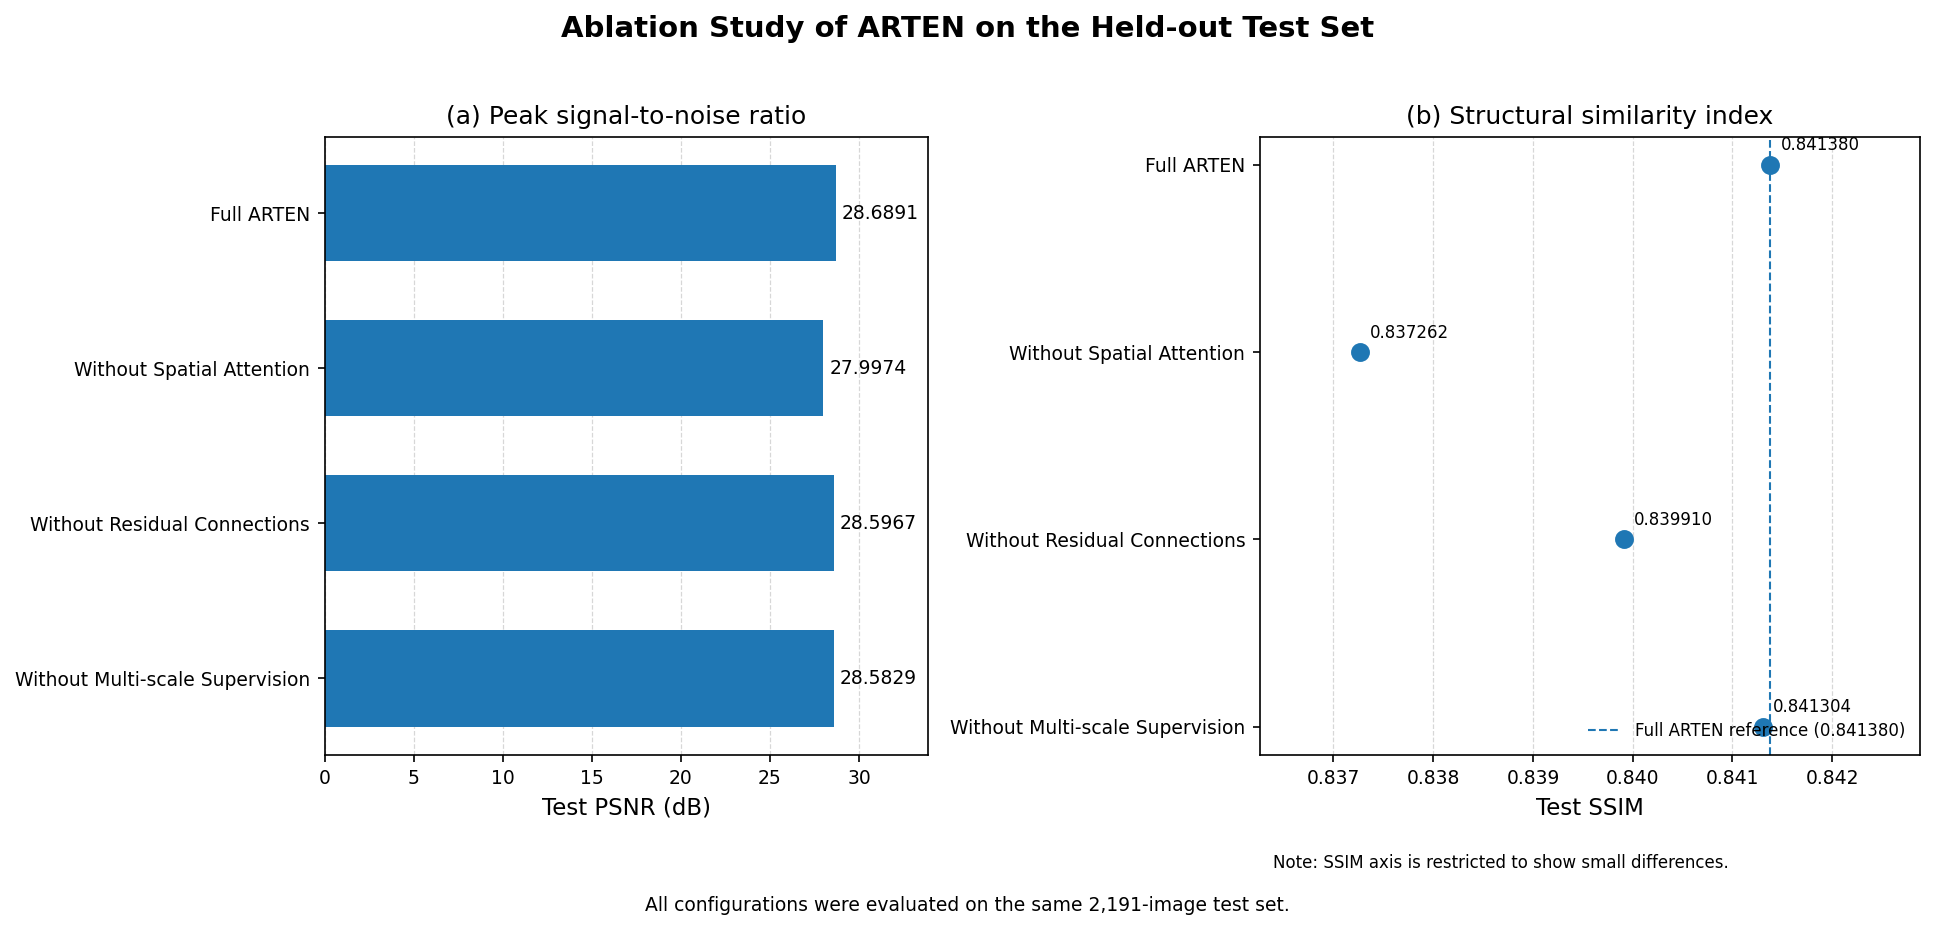


FIGURE EXPORT VERIFICATION
PASS: ARTEN_Ablation_Comparison.png (625,982 bytes)
PASS: ARTEN_Ablation_Comparison.tiff (115,186,286 bytes)
PASS: ARTEN_Ablation_Comparison.pdf (28,056 bytes)

All three figure formats were exported successfully.
Output directory: /home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study/consolidated_results


In [38]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load the consolidated results
# ------------------------------------------------------------
PROJECT_DIR = Path(
    "/home/ex5/Desktop/ARTEN_Project/ARTEN_Ablation_Study"
)

RESULTS_DIR = PROJECT_DIR / "consolidated_results"

CSV_PATH = RESULTS_DIR / "ARTEN_Ablation_Consolidated_Results.csv"

if not CSV_PATH.is_file():
    raise FileNotFoundError(
        f"Consolidated CSV not found: {CSV_PATH}"
    )

df = pd.read_csv(CSV_PATH)

required_columns = [
    "Model",
    "Test_PSNR_dB",
    "Test_SSIM",
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if len(df) != 4:
    raise ValueError(
        f"Expected 4 model records; found {len(df)}."
    )

# Display names for the manuscript
display_names = {
    "Full_ARTEN": "Full ARTEN",
    "Without_Spatial_Attention": "Without Spatial Attention",
    "Without_Residual_Connections": "Without Residual Connections",
    "Without_MultiScale_Supervision": "Without Multi-scale Supervision",
}

df["Display_Model"] = df["Model"].map(display_names)

if df["Display_Model"].isna().any():
    raise ValueError("An unexpected model name was found in the CSV.")

# Fixed ordering: full model first, then the three ablations
model_order = [
    "Full ARTEN",
    "Without Spatial Attention",
    "Without Residual Connections",
    "Without Multi-scale Supervision",
]

df["Display_Model"] = pd.Categorical(
    df["Display_Model"],
    categories=model_order,
    ordered=True,
)

df = df.sort_values("Display_Model").reset_index(drop=True)

# ------------------------------------------------------------
# 2. Prepare publication-quality figure
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
})

fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5.8),
    gridspec_kw={"width_ratios": [1.05, 1.15]},
)

y = np.arange(len(df))
labels = df["Display_Model"].astype(str).tolist()

# ------------------------------------------------------------
# 3. Panel A: PSNR horizontal bar chart
# ------------------------------------------------------------
psnr = df["Test_PSNR_dB"].to_numpy()

bars = ax1.barh(y, psnr, height=0.62)

ax1.set_yticks(y)
ax1.set_yticklabels(labels)
ax1.invert_yaxis()
ax1.set_xlabel("Test PSNR (dB)")
ax1.set_title("(a) Peak signal-to-noise ratio")
ax1.set_xlim(0, max(psnr) * 1.18)
ax1.grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.5)
ax1.set_axisbelow(True)

for bar, value in zip(bars, psnr):
    ax1.text(
        value + max(psnr) * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        ha="left",
        fontsize=9,
    )

# ------------------------------------------------------------
# 4. Panel B: SSIM dot plot
# A narrow, explicitly labelled range makes small differences
# visible without using misleading zero-baseline bars.
# ------------------------------------------------------------
ssim = df["Test_SSIM"].to_numpy()

ax2.scatter(
    ssim,
    y,
    s=65,
    zorder=3,
)

full_ssim = float(
    df.loc[df["Model"] == "Full_ARTEN", "Test_SSIM"].iloc[0]
)

ax2.axvline(
    full_ssim,
    linestyle="--",
    linewidth=1.0,
    label=f"Full ARTEN reference ({full_ssim:.6f})",
)

ax2.set_yticks(y)
ax2.set_yticklabels(labels)
ax2.invert_yaxis()
ax2.set_xlabel("Test SSIM")
ax2.set_title("(b) Structural similarity index")
ax2.set_xlim(
    float(ssim.min()) - 0.0010,
    float(ssim.max()) + 0.0015,
)
ax2.grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.5)
ax2.set_axisbelow(True)
ax2.legend(loc="lower right", fontsize=8, frameon=False)

for index, value in enumerate(ssim):
    ax2.annotate(
        f"{value:.6f}",
        xy=(value, index),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=8,
        ha="left",
    )

# Explicitly disclose the truncated SSIM axis.
ax2.text(
    0.02,
    -0.16,
    "Note: SSIM axis is restricted to show small differences.",
    transform=ax2.transAxes,
    fontsize=8,
    ha="left",
    va="top",
)

# ------------------------------------------------------------
# 5. Figure title and layout
# ------------------------------------------------------------
fig.suptitle(
    "Ablation Study of ARTEN on the Held-out Test Set",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.5,
    -0.01,
    "All configurations were evaluated on the same 2,191-image test set.",
    ha="center",
    fontsize=9,
)

fig.tight_layout()

# ------------------------------------------------------------
# 6. Export in common publication formats
# ------------------------------------------------------------
png_path = RESULTS_DIR / "ARTEN_Ablation_Comparison.png"
tiff_path = RESULTS_DIR / "ARTEN_Ablation_Comparison.tiff"
pdf_path = RESULTS_DIR / "ARTEN_Ablation_Comparison.pdf"

fig.savefig(png_path, dpi=600, bbox_inches="tight")
fig.savefig(tiff_path, dpi=600, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()

# ------------------------------------------------------------
# 7. Verify exported files
# ------------------------------------------------------------
print("\nFIGURE EXPORT VERIFICATION")
for path in [png_path, tiff_path, pdf_path]:
    if not path.is_file() or path.stat().st_size == 0:
        raise RuntimeError(f"Figure export failed: {path}")

    print(f"PASS: {path.name} ({path.stat().st_size:,} bytes)")

print("\nAll three figure formats were exported successfully.")
print(f"Output directory: {RESULTS_DIR}")
